In [ ]:
import random as rd
import torch
import torchvision.transforms.functional as TF
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
import matplotlib.pyplot as plt
from typing import Optional
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import mobilenet_v3_small, shufflenet_v2_x2_0, mobilenet_v2, efficientnet_b0, squeezenet1_1
from torch import Tensor
import torch.optim as optim
import copy
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import classification_report
import time
from wtconv import WTConv2d
from ultralytics import YOLO

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

def set_seed(seed=13):
    rd.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

Using device: cuda


In [9]:
SIZE = (64,64)
BATCH_SIZE = 512

resize_and_norm = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize(SIZE),
    transforms.ToTensor(),
])

class TrainDataset(Dataset):
    total_augmentasi = 7

    def __init__(self, dataset, index):
        self.dataset = dataset
        self.index = index

    def __len__(self):
        return len(self.index) * self.total_augmentasi

    def zoom(self, image, scale):
        w, h = image.size
        new_w, new_h = (w // scale), (h // scale)
        left = (w - new_w) // 2
        top = (h - new_h) // 2
        image = image.crop((left, top, left + new_w, top + new_h))
        return image.resize((w, h))

    def __getitem__(self, index):
        original_pos = index // self.total_augmentasi
        version = index % self.total_augmentasi
        real_idx = self.index[original_pos]

        label = self.dataset[real_idx]['label']
        image = self.dataset[real_idx]['image']

        if version == 0:
            pass
        elif version == 1:
            image = TF.hflip(image)
        elif version == 2:
            image = TF.vflip(image)
        elif version == 3:
            image = self.zoom(image, np.random.uniform(1.15, 1.3))
        else:
            image = TF.resize(image, SIZE)
            image = TF.rotate(image, np.random.randint(180), expand=True)

        image = resize_and_norm(image)
        return image, label


class ValDataset(Dataset):
    def __init__(self, dataset, index):
        self.dataset = dataset
        self.index = index

    def __len__(self):
        return len(self.index)

    def __getitem__(self, idx):
        real_idx = self.index[idx]
        label = self.dataset[real_idx]['label']
        image = self.dataset[real_idx]['image']
        image = resize_and_norm(image)
        return image, label


train_dataset = TrainDataset(ds['train'], train_idx)
val_dataset = ValDataset(ds['train'], val_idx)
test_dataset = ValDataset(ds['train'], test_idx)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=10, pin_memory=True,
                           persistent_workers=True, prefetch_factor=4)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=2, pin_memory=True, persistent_workers=True)

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=2, pin_memory=True, persistent_workers=True)

weighted_class = [len(train_idx) / (len(ds['train'].features['label'].names) * cnt) for i, cnt in enumerate(arr_train)]

balance_factor = 0.999
class_balanced_weight = [(1 - balance_factor) / (1 - balance_factor**cnt) for cnt in arr_train] 

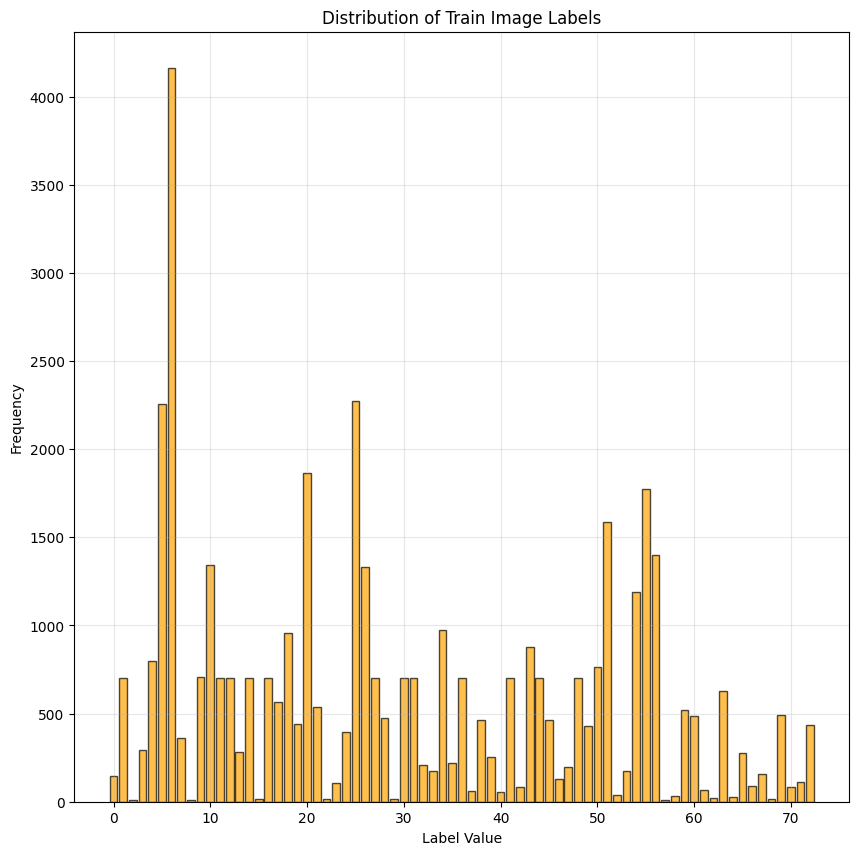

In [ ]:
plt.figure(figsize=(10, 10))

labels = [i for i in range(len(ds['train'].features['label'].names))]
counts = arr_train

plt.bar(labels, counts, color='orange', alpha=0.7, edgecolor='black')
plt.xlabel('Label Value')
plt.ylabel('Frequency')
plt.title('Distribution of Train Image Labels')
plt.grid(True, alpha=0.3)
plt.show()

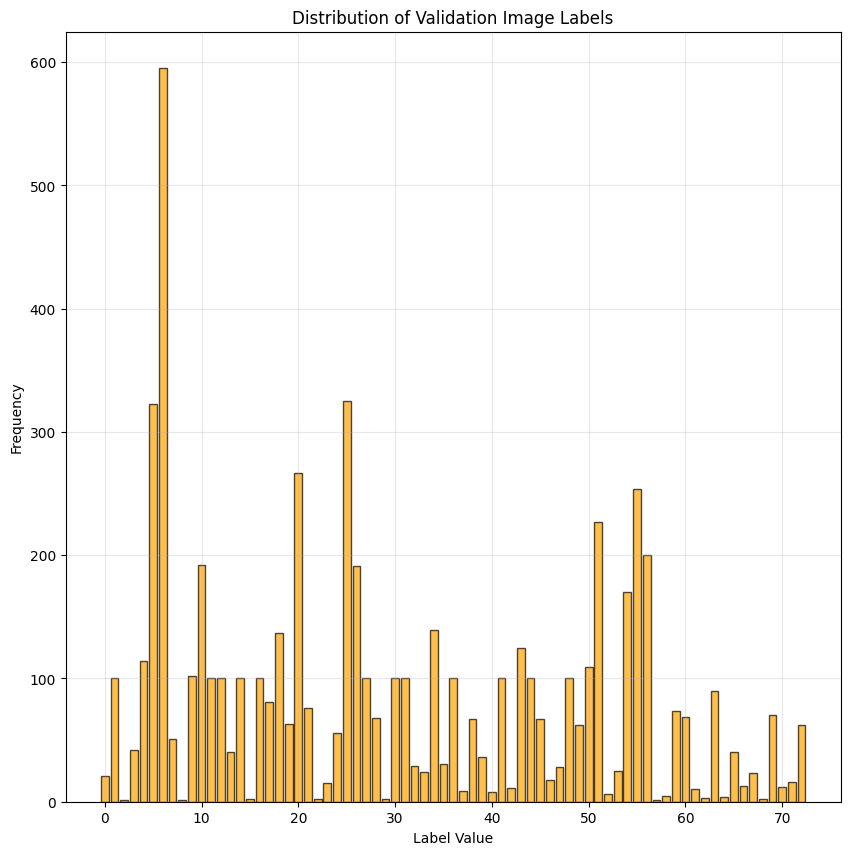

In [ ]:
plt.figure(figsize=(10, 10))

labels = [i for i in range(len(ds['train'].features['label'].names))]
counts = arr_val

plt.bar(labels, counts, color='orange', alpha=0.7, edgecolor='black')
plt.xlabel('Label Value')
plt.ylabel('Frequency')
plt.title('Distribution of Validation Image Labels')
plt.grid(True, alpha=0.3)
plt.show()

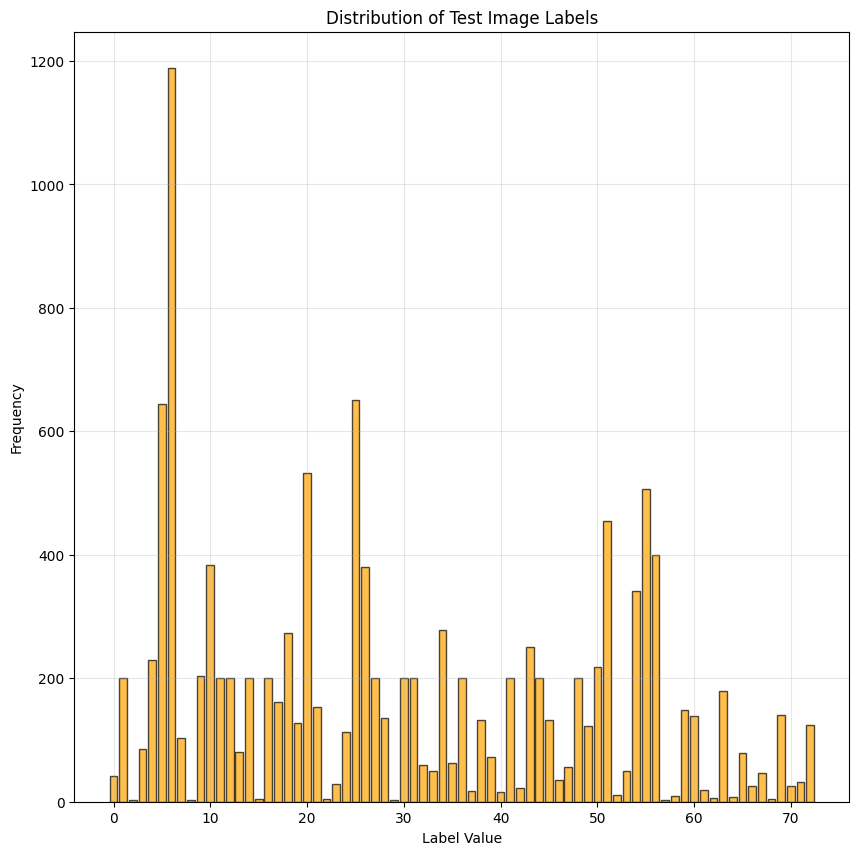

In [ ]:
plt.figure(figsize=(10, 10))

labels = [i for i in range(len(ds['train'].features['label'].names))]
counts = arr_test

plt.bar(labels, counts, color='orange', alpha=0.7, edgecolor='black')
plt.xlabel('Label Value')
plt.ylabel('Frequency')
plt.title('Distribution of Test Image Labels')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
class ConvBNAct(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1, groups=1, use_act=True):
        super().__init__()
        self.act = nn.SiLU()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, stride=stride, padding=padding, groups=groups)
        self.bn = nn.BatchNorm2d(out_channels)
        self.use_act = use_act

    def forward(self, x):
        out = self.conv(x)
        out = self.bn(out)
        if self.use_act:
            out = self.act(out)
        return out

class DWConv(nn.Module):
    def __init__(self, in_channels, stride=2):
        super().__init__()
        self.network = ConvBNAct(in_channels, in_channels, groups=in_channels, stride=stride)

    def forward(self, x):
        return self.network(x)

class HGStem(nn.Module):
    def __init__(self, in_channels, mid_channels, out_channels):
        super().__init__()
        self.stem1 = ConvBNAct(in_channels, mid_channels, kernel_size=3, stride=2)
        self.stem2 = ConvBNAct(mid_channels, mid_channels, kernel_size=2, stride=1, padding=0)
        self.stem3 = ConvBNAct(mid_channels * 2, mid_channels, kernel_size=3, stride=2)
        self.stem4 = ConvBNAct(mid_channels, out_channels, kernel_size=1, stride=1, padding=0)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=1, ceil_mode=True)

    def _pad_same(self, x, kernel_size=2):
        x = F.pad(x, (0, 1, 0, 1))
        return x

    def forward(self, x):
        x = self.stem1(x)

        x2 = self._pad_same(x)
        x2 = self.stem2(x2)

        x1 = self._pad_same(x)
        x1 = self.pool(x1)

        x = torch.cat([x1, x2], dim=1)
        x = self.stem3(x)
        x = self.stem4(x)
        return x

class GhostBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, ratio=2, use_act=True):
        super().__init__()
        init_ch = out_channels // ratio
        new_ch = out_channels - init_ch

        self.primary = ConvBNAct(in_channels, init_ch, 1, stride=1, padding=0, use_act=False)
        self.cheap_dw = ConvBNAct(init_ch, init_ch, kernel_size, stride=1, padding=kernel_size//2, groups=init_ch, use_act=use_act)
        self.cheap_pw = ConvBNAct(init_ch, new_ch, 1, stride=1, padding=0, use_act=use_act)

    def forward(self, x):
        x1 = self.primary(x)
        x2 = self.cheap_dw(x1)
        x2 = self.cheap_pw(x2)
        return torch.cat([x1, x2], dim=1)

class ESE(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Conv2d(channels, channels, kernel_size=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        weight = self.gap(x)
        weight = self.sigmoid(self.fc(weight))
        return x * weight

class H2GBlock(nn.Module):
    def __init__(self, in_channels, mid_channels, layer_num=5):
        super().__init__()
        out_channels = in_channels
        self.layers = nn.ModuleList()
        for i in range(layer_num):
            self.layers.append(GhostBlock(in_channels if i == 0 else mid_channels, mid_channels, 3))

        total_ch = in_channels + layer_num * mid_channels
        self.conv1 = ConvBNAct(total_ch, out_channels, kernel_size=1, padding=0)
        self.ese = ESE(out_channels)

    def forward(self, x):
        identity = x
        output = []
        output.append(x)
        for layer in self.layers:
            x = layer(x)
            output.append(x)
        x = torch.cat(output, dim=1)
        x = self.conv1(x)
        x = self.ese(x)
        x += identity
        return x

class Bottleneck(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.network = nn.Sequential(ConvBNAct(in_channels, in_channels), ConvBNAct(in_channels, in_channels))

    def forward(self, x):
        identity = x
        x = self.network(x)
        x += identity
        return x

class C2f(nn.Module):
    def __init__(self, in_channels, out_channels, num_layer=3):
        super().__init__()
        self.conv1 = ConvBNAct(in_channels, out_channels)
        self.bottlenecks = nn.ModuleList(Bottleneck(out_channels // 2) for _ in range(num_layer))
        self.conv2 = ConvBNAct(int(0.5 * (num_layer + 2) * out_channels), out_channels, kernel_size=1, padding=0)

    def forward(self, x):
        x = self.conv1(x)
        chunks = list(x.chunk(2, dim=1))

        for bottleneck in self.bottlenecks:
            chunks.append(bottleneck(chunks[-1]))

        x = torch.cat(chunks, dim=1)
        x = self.conv2(x)
        return x

class ADown(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = ConvBNAct(in_channels // 2, out_channels // 2, stride=2)
        self.conv2 = ConvBNAct(in_channels // 2, out_channels // 2, kernel_size=1, padding=0)
        self.avgpool = nn.AvgPool2d(kernel_size=2, stride=1, padding=0)
        self.maxpool = nn.MaxPool2d(2)

    def forward(self, x):
        x = F.pad(x, (0, 1, 0, 1))
        x = self.avgpool(x)
        chunks = list(x.chunk(2, dim=1))
        x1 = self.conv1(chunks[0])
        x2 = self.maxpool(chunks[1])
        x2 = self.conv2(x2)
        x = torch.cat([x1, x2], dim=1)
        return x

class ConvGN(nn.Module):
    def __init__(self, in_channels, out_channels, num_groups, kernel_size=3, stride=1, padding=1, groups=1, use_act=True):
        super().__init__()
        self.act = nn.SiLU()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, stride=stride, padding=padding, groups=groups)
        self.gn = nn.GroupNorm(num_groups, out_channels)
        self.use_act = use_act

    def forward(self, x):
        out = self.conv(x)
        out = self.gn(out)
        if self.use_act:
            out = self.act(out)
        return out

class LSCD_Clsf(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.network = nn.Sequential(
            ConvGN(in_channels, out_channels, out_channels // 2),
            ConvGN(out_channels, out_channels, out_channels // 4),
            ConvGN(out_channels, out_channels, 1))
        self.linear = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten())

    def forward(self, x):
        x = self.network(x)
        x = self.linear(x)
        return x

class Plank_li_net(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.backbone1 = nn.Sequential(HGStem(1, 16, 32), H2GBlock(32, 32), DWConv(32), H2GBlock(32, 32))
        self.backbone2 = nn.Sequential(DWConv(32), H2GBlock(32, 32), H2GBlock(32, 32))
        self.backbone3 = nn.Sequential(DWConv(32), H2GBlock(32, 32))
        self.upsample = nn.Upsample(scale_factor=2, mode='nearest')
        self.c2f_b3_b2 = C2f(64, 64)
        self.c2f_b2_b1 = C2f(96, 96)
        self.adown1 = ADown(96, 64)
        self.adown2 = ADown(128, 96)
        self.c2f0 = C2f(128, 128)
        self.c2f1 = C2f(128, 128)
        self.lscd1 = LSCD_Clsf(96, 96)
        self.lscd2 = LSCD_Clsf(128, 128)
        self.lscd3 = LSCD_Clsf(128, 128)
        self.linear = nn.Linear(352, num_classes)

    def forward(self, x):
        b1 = self.backbone1(x)
        b2 = self.backbone2(b1)
        b3 = self.backbone3(b2)
        b3_up = self.upsample(b3)
        b3_b2_cat = torch.cat([b2, b3_up], dim=1)
        b3_b2_cat = self.c2f_b3_b2(b3_b2_cat)
        b2_up = self.upsample(b3_b2_cat)
        b2_b1_cat = torch.cat([b1, b2_up], dim=1)
        b2_b1_cat = self.c2f_b2_b1(b2_b1_cat)
        adown_b2_b1 = self.adown1(b2_b1_cat)
        adown_b3_b2_cat = torch.cat([adown_b2_b1, b3_b2_cat], dim=1)
        adown_b3_b2_cat = self.c2f0(adown_b3_b2_cat)
        adown_last = self.adown2(adown_b3_b2_cat)
        adown_last_b3_cat = torch.cat([adown_last, b3], dim=1)
        adown_last_b3_cat = self.c2f1(adown_last_b3_cat)
        final_cat = torch.cat([self.lscd1(b2_b1_cat), self.lscd2(adown_b3_b2_cat), self.lscd3(adown_last_b3_cat)], dim=1)
        return self.linear(final_cat)

class SiReconBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1), nn.BatchNorm2d(out_ch)
        )
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.net(x) + self.proj(x))

class Plank_SiRecon(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            SiReconBlock(1, 32), nn.MaxPool2d(2),
            SiReconBlock(32, 64), nn.MaxPool2d(2),
            SiReconBlock(64, 128), nn.MaxPool2d(2),
            SiReconBlock(128, 256),
        )
        self.linear = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.linear(self.network(x))

class SiDSCConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.proj = nn.Sequential(nn.Conv2d(in_channels, out_channels, 1), nn.BatchNorm2d(out_channels))
        self.relu = nn.ReLU()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels, in_channels, 3, padding=1, groups=in_channels), nn.BatchNorm2d(in_channels), nn.ReLU(),
            nn.Conv2d(in_channels, out_channels, 1), nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, groups=out_channels), nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 1), nn.BatchNorm2d(out_channels)
        )

    def forward(self, x):
        out = self.network(x)
        out = out + self.proj(x)
        return self.relu(out)

class Plank_SiDSC(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.linear = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(512, num_classes))
        self.network = nn.Sequential(
            SiDSCConv(1, 64), nn.MaxPool2d(2),
            SiDSCConv(64, 128), nn.MaxPool2d(2),
            SiDSCConv(128, 256), nn.MaxPool2d(2),
            SiDSCConv(256, 512),
        )

    def forward(self, x):
        out = self.network(x)
        return self.linear(out)

class MGLR_Att(nn.Module):
    def __init__(self, input_ch):
        super().__init__()
        self.down_sampling = nn.Sequential(
            nn.AvgPool2d(2), ConvBNAct(input_ch, input_ch, 1, use_act=False, padding=0),
        )
        self.hori_1_5 = nn.Conv2d(input_ch, input_ch, kernel_size=(1,5), padding=(0,2), groups=input_ch)
        self.hori_1_7 = nn.Conv2d(input_ch, input_ch, kernel_size=(1,7), padding=(0,3), groups=input_ch)
        self.hori_1_9 = nn.Conv2d(input_ch, input_ch, kernel_size=(1,9), padding=(0,4), groups=input_ch)
        self.ver_5_1 = nn.Conv2d(input_ch, input_ch, kernel_size=(5,1), padding=(2,0), groups=input_ch)
        self.ver_7_1 = nn.Conv2d(input_ch, input_ch, kernel_size=(7,1), padding=(3,0), groups=input_ch)
        self.ver_9_1 = nn.Conv2d(input_ch, input_ch, kernel_size=(9,1), padding=(4,0), groups=input_ch)
        self.sigmoid = nn.Sigmoid()
        self.norm = nn.BatchNorm2d(input_ch)

    def forward(self, x):
        target_size = x.shape[-2:] 
        downsampling = self.down_sampling(x)

        hor_1_5 = self.hori_1_5(downsampling)
        hor_1_5 = hor_1_5 * self.sigmoid(hor_1_5)

        hor_1_7 = self.hori_1_7(downsampling)
        hor_1_7 = hor_1_7 * self.sigmoid(hor_1_7)

        hor_1_9 = self.hori_1_9(downsampling)
        hor_1_9 = hor_1_9 * self.sigmoid(hor_1_9)

        horizontal_gate = hor_1_5 + hor_1_7 + hor_1_9
        horizontal_gate = self.norm(horizontal_gate)

        ver_5_1 = self.ver_5_1(horizontal_gate)
        ver_5_1 = ver_5_1 * self.sigmoid(ver_5_1)

        ver_7_1 = self.ver_7_1(horizontal_gate)
        ver_7_1 = ver_7_1 * self.sigmoid(ver_7_1)

        ver_9_1 = self.ver_9_1(horizontal_gate)
        ver_9_1 = ver_9_1 * self.sigmoid(ver_9_1)

        vertical_gate = ver_5_1 + ver_7_1 + ver_9_1
        vertical_gate = self.sigmoid(vertical_gate)

        vertical_gate = F.interpolate(vertical_gate, size=target_size, mode='bilinear', align_corners=False)
        return vertical_gate

class MWG_Bneck(nn.Module):
    def __init__(self, input_ch, exp_ch, out_ch, kernel_size, stride=1):
        super().__init__()
        self.stride = stride
        self.G_module1 = GhostBlock(input_ch, exp_ch, kernel_size, use_act=False)   
        self.G_module2 = GhostBlock(exp_ch, out_ch, kernel_size, use_act=False)     
        self.norm1 = nn.BatchNorm2d(exp_ch)
        self.norm2 = nn.BatchNorm2d(out_ch)
        self.mglr = MGLR_Att(exp_ch)
        self.relu = nn.ReLU()

        if stride == 2:
            self.wtconv = WTConv2d(exp_ch, exp_ch, kernel_size, stride=2)
            self.shortcut = nn.Sequential(
                DWConv(input_ch, stride=2),
                ConvBNAct(input_ch, out_ch, kernel_size=1, padding=0, use_act=False),
            )
        elif input_ch != out_ch:
            self.shortcut = ConvBNAct(input_ch, out_ch, kernel_size=1, padding=0, use_act=False)
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        gm1 = self.relu(self.norm1(self.G_module1(x)))   
        att = self.mglr(gm1)                                
        fusion = gm1 * att

        if self.stride == 2:
            fusion = self.wtconv(fusion)
            gm2 = self.norm2(self.G_module2(fusion))
            return self.shortcut(x) + gm2
        else:
            gm2 = self.norm2(self.G_module2(fusion))
            return self.shortcut(x) + gm2

class MWC_GhostNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.conv1 = ConvBNAct(1, 4, kernel_size=3, stride=1, padding=1)

        self.stage1 = nn.Sequential(
            MWG_Bneck(4, 4, 4, kernel_size=3, stride=1),
        )

        self.stage2 = nn.Sequential(
            MWG_Bneck(4, 12, 6, kernel_size=3, stride=1),
            MWG_Bneck(6, 18, 6, kernel_size=3, stride=1),
        )

        self.stage3 = nn.Sequential(
            MWG_Bneck(6, 18, 10, kernel_size=5, stride=2),
            MWG_Bneck(10, 30, 10, kernel_size=5, stride=1),
        )

        self.stage4 = nn.Sequential(
            MWG_Bneck(10, 60, 20, kernel_size=3, stride=2),
            MWG_Bneck(20, 50, 20, kernel_size=3, stride=1),
            MWG_Bneck(20, 46, 20, kernel_size=3, stride=1),
            MWG_Bneck(20, 46, 20, kernel_size=3, stride=1),
        )

        self.stage5 = nn.Sequential(
            MWG_Bneck(20, 120, 28, kernel_size=3, stride=1),
            MWG_Bneck(28, 168, 28, kernel_size=3, stride=1),
        )

        self.stage6 = nn.Sequential(
            MWG_Bneck(28, 168, 40, kernel_size=5, stride=2),
            MWG_Bneck(40, 240, 40, kernel_size=5, stride=1),
            MWG_Bneck(40, 240, 40, kernel_size=5, stride=1),
            MWG_Bneck(40, 240, 40, kernel_size=5, stride=1),
            MWG_Bneck(40, 240, 40, kernel_size=5, stride=1),
        )

        self.conv2 = ConvBNAct(40, 240, kernel_size=1, stride=1, padding=0)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.conv3 = ConvBNAct(240, 320, kernel_size=1, stride=1, padding=0)
        self.classifier = nn.Linear(320, num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.stage5(x)
        x = self.stage6(x)
        x = self.conv2(x)
        x = self.avgpool(x)
        x = self.conv3(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

class ReductionModule(nn.Module):
    def __init__(self, input_ch, out_ch):
        super().__init__()
        self.conv1 = ConvBNAct(input_ch, out_ch // 2, kernel_size=1, padding=0)
        self.conv2 = ConvBNAct(out_ch // 2, out_ch // 2, kernel_size=3, stride=2)
        self.maxpool = nn.MaxPool2d(2, stride=2, ceil_mode=True)

    def forward(self, x):
        x = self.conv1(x)
        b1 = self.conv2(x)
        b2 = self.maxpool(x)
        cat = torch.cat([b1, b2], dim=1)
        return cat

class AttentionModule(nn.Module):
    def __init__(self, input_ch, out_ch):
        super().__init__()
        self.conv1 = ConvBNAct(input_ch, out_ch // 2, kernel_size=1, padding=0)
        self.conv2 = ConvBNAct(out_ch // 2, out_ch // 2, kernel_size=1, padding=0, groups=8)
        self.conv3 = ConvBNAct(out_ch // 2, out_ch // 2, kernel_size=3, groups=8)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.conv1(x)
        b1 = self.conv2(x)
        b1_sig = self.sigmoid(b1)
        b1 = b1 * b1_sig
        b2 = self.conv3(x)
        b2_sig = self.sigmoid(b2)
        b2 = b2 * b2_sig
        cat = torch.cat([b1, b2], dim=1)
        return cat

class TANet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            ConvBNAct(1, 64), ReductionModule(64, 32), AttentionModule(32, 128),
            AttentionModule(128, 128), ReductionModule(128, 32), AttentionModule(32, 256),
            AttentionModule(256, 256), ReductionModule(256, 32), AttentionModule(32, 384),
            AttentionModule(384, 512), ConvBNAct(512, num_classes), nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

    def forward(self, x):
        x = self.network(x)
        return x

class h_sigmoid(nn.Module):
    def __init__(self, inplace=True):
        super(h_sigmoid, self).__init__()
        self.relu = nn.ReLU6(inplace=inplace)

    def forward(self, x):
        return self.relu(x + 3) / 6

class h_swish(nn.Module):
    def __init__(self, inplace=True):
        super(h_swish, self).__init__()
        self.sigmoid = h_sigmoid(inplace=inplace)

    def forward(self, x):
        return x * self.sigmoid(x)

class CoordAtt(nn.Module):
    def __init__(self, inp, oup, reduction=32):
        super(CoordAtt, self).__init__()
        self.pool_h = nn.AdaptiveAvgPool2d((None, 1))
        self.pool_w = nn.AdaptiveAvgPool2d((1, None))

        mip = max(8, inp // reduction)

        self.conv1 = nn.Conv2d(inp, mip, kernel_size=1, stride=1, padding=0)
        self.bn1 = nn.BatchNorm2d(mip)
        self.act = h_swish()
        
        self.conv_h = nn.Conv2d(mip, oup, kernel_size=1, stride=1, padding=0)
        self.conv_w = nn.Conv2d(mip, oup, kernel_size=1, stride=1, padding=0)
        

    def forward(self, x):
        identity = x
        
        n,c,h,w = x.size()
        x_h = self.pool_h(x)
        x_w = self.pool_w(x).permute(0, 1, 3, 2)

        y = torch.cat([x_h, x_w], dim=2)
        y = self.conv1(y)
        y = self.bn1(y)
        y = self.act(y) 
        
        x_h, x_w = torch.split(y, [h, w], dim=2)
        x_w = x_w.permute(0, 1, 3, 2)

        a_h = self.conv_h(x_h).sigmoid()
        a_w = self.conv_w(x_w).sigmoid()

        out = identity * a_w * a_h

        return out

def yolo_model(model, num_classes):
    old_conv = model.model[0].conv
    new_conv = nn.Conv2d(
        in_channels=1,
        out_channels=old_conv.out_channels,
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=old_conv.bias is not None
    )
    model.model[0].conv = new_conv
    old_linear = model.model[-1].linear
    new_linear = nn.Linear(in_features=old_linear.in_features, out_features=num_classes, bias=old_linear.bias is not None)
    model.model[-1].linear = new_linear
    model = model.float()
    for name, layer in model.named_modules():
        if hasattr(layer, 'reset_parameters'):
            layer.reset_parameters()
    for p in model.parameters():
        p.requires_grad = True
    return model

def create_model(model_name, num_classes, device, input_size=None):
    if model_name == 'linet':
        model = Plank_li_net(num_classes).to(device)
    elif model_name == 'Si-Recon':
        model = Plank_SiRecon(num_classes).to(device)
    elif model_name == 'Si-DSC':
        model = Plank_SiDSC(num_classes).to(device)
    elif model_name == 'mwc-g':
        model = MWC_GhostNet(num_classes).to(device)
    elif model_name == 'tanet':
        model = TANet(num_classes).to(device)
    elif model_name == 'yolo8':
        model = YOLO("yolov8s-cls.pt").model
        model = yolo_model(model, num_classes)
        model.to(device)
    elif model_name == 'yolo11':
        model = YOLO("yolo11s-cls.pt").model
        model = yolo_model(model, num_classes)
        model.to(device)
    elif model_name == 'yolo26':
        model = YOLO("yolo26s-cls.pt").model
        model = yolo_model(model, num_classes)
        model.to(device)
    elif model_name == 'mobilenetv3':
        model = mobilenet_v3_small(weights=None)

        old_conv = model.features[0][0]
        model.features[0][0] = nn.Conv2d(
            in_channels=1,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=old_conv.bias is not None,
        )

        in_features = model.classifier[3].in_features
        model.classifier[3] = nn.Linear(in_features, num_classes)
        model.to(device)
    elif model_name == 'mobilenetv2':
        model = mobilenet_v2(weights=None)

        old_conv = model.features[0][0]
        model.features[0][0] = nn.Conv2d(
            in_channels=1,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=old_conv.bias is not None,
        )

        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)
        model.to(device)
    elif model_name == 'shufflenetv2':
        model = shufflenet_v2_x2_0(weights=None)
        old_conv = model.conv1[0]
        model.conv1[0] = nn.Conv2d(
            in_channels=1,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=old_conv.bias is not None,
        )
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)
        model.to(device)
    elif model_name == 'efficientnetb0':
        model = efficientnet_b0(weights=None)

        old_conv = model.features[0][0]
        model.features[0][0] = nn.Conv2d(
            in_channels=1,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=old_conv.bias is not None,
        )
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)
        model.to(device) 
    elif model_name == 'squeezenet':
        model = squeezenet1_1(weights=None)
        old_conv = model.features[0]
        model.features[0] = nn.Conv2d(
            in_channels=1,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=old_conv.bias is not None,
        )
        old_cls = model.classifier[1]
        model.classifier[1] = nn.Conv2d(
            in_channels=old_cls.in_channels,
            out_channels=num_classes,
            kernel_size=old_cls.kernel_size,
            stride=old_cls.stride,
            padding=old_cls.padding,
            bias=old_cls.bias is not None,
        )
        model.to(device) 
    else:
        raise ValueError(f"Unknown model: {model_name}")

    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total params: {total:,}  |  Trainable: {trainable:,}")
    return model

In [11]:
class Focal_Loss(nn.CrossEntropyLoss):
    __constants__ = ["ignore_index", "reduction", "label_smoothing"]
    ignore_index: int
    label_smoothing: float

    def __init__(
        self,
        weight: Optional[Tensor] = None,
        size_average=None,
        ignore_index: int = -100,
        reduce=None,
        reduction: str = "none",
        label_smoothing: float = 0.0,
    ) -> None:
        super().__init__(weight, size_average, ignore_index, reduce, reduction, label_smoothing)
        self.ignore_index = ignore_index
        self.label_smoothing = label_smoothing

    def forward(self, input: Tensor, target: Tensor, alpha: Tensor) -> Tensor:
        ce = F.cross_entropy(
            input,
            target,
            weight=self.weight,
            ignore_index=self.ignore_index,
            reduction=self.reduction,
            label_smoothing=self.label_smoothing,
        )

        #fl = []

        #for i in range(len(target)):
        #    fl.append(alpha[target[i]]*((1-torch.exp(-ce[i]))**2)*ce[i])

        #return torch.stack(fl).mean()
        alpha_t = alpha[target]  
        fl = alpha_t * (1 - torch.exp(-ce))**2 * ce
        return fl.mean()

In [ ]:
model_name = 'mwc-g'
model = create_model(model_name, len(ds['train'].features['label'].names), device)
lr = 5e-3
epochs = 50

criterion = Focal_Loss()
optimizer = optim.Adam(model.parameters(), lr=lr)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=5e-6)

Total params: 2,316,809  |  Trainable: 2,316,809


In [ ]:
def get_logits(out):
    return out[1] if isinstance(out, (tuple, list)) else out

val_loss_hist = []
val_acc_hist = []
loss_hist = []
acc_hist = []
log_file = "training.log"
best_model = copy.deepcopy(model)
best_val_acc = 0

for epoch in range(epochs):
  t_ep = time.time()
  running_loss = 0.0
  correct = 0

  model.train()
  for inputs, labels in train_loader:
    inputs = inputs.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)
    #inputs = inputs.unsqueeze(1)
    optimizer.zero_grad()

    outputs = model(inputs)
    loss = criterion(outputs, labels, torch.tensor(weighted_class, dtype=torch.float32, device=device))
    loss.backward()
    optimizer.step()
    running_loss += loss.item()

    softmax = nn.Softmax(dim=1)
    probs = softmax(outputs)
    correct += (outputs.argmax(1) == labels).sum().item()

  scheduler.step()
  avg_loss = running_loss / len(train_loader)
  accuracy = correct / (len(train_idx) * 7)
  loss_hist.append(avg_loss)
  acc_hist.append(accuracy)

  model.eval()
  correct_val = 0
  val_loss = 0.0
  with torch.no_grad():
    for inputs, labels in val_loader:
      img = inputs.to(device)
      label = labels.to(device)

      outputs = get_logits(model(img))
      loss = criterion(outputs, label, torch.tensor(weighted_class, dtype=torch.float32, device=device))
      val_loss += loss.item()
      softmax = nn.Softmax(dim=1)
      probs = softmax(outputs)
      predicted_label = torch.argmax(probs, dim=1)
      correct_val += (outputs.argmax(1) == label).sum().item()
  avg_val_loss = val_loss / len(val_loader)
  val_acc = correct_val / len(val_idx)
  val_loss_hist.append(avg_val_loss)
  val_acc_hist.append(val_acc)
  if val_acc > best_val_acc:
      best_val_acc = val_acc
      best_model = copy.deepcopy(model)
  ep_time = time.time() - t_ep
  log_line = f"Epoch [{epoch+1}/{epochs}] - Average loss: {avg_loss:.4f} - Accuracy: {accuracy:.4f} - Val_Loss: {avg_val_loss:.4f} - Val_Acc: {val_acc:.4f} - LR: {scheduler.get_last_lr()[0]:.2e} - Time: {ep_time:.1f}s"
  print(log_line)
  with open(log_file, "a") as f:
      f.write(log_line + "\n")

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(loss_hist, label='Training Loss')
plt.plot(val_loss_hist, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.savefig("loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(val_acc_hist, label='Validation Accuracy')
plt.plot(acc_hist, label='Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.savefig("accuracy_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
all_preds = []
all_labels = []

best_model.eval()
with torch.no_grad():
    correct = 0
    val_loss = 0.0

    for inputs, labels in test_loader:
        img = inputs.to(device)
        label = labels.to(device)

        outputs = get_logits(best_model(img))
        loss = criterion(outputs, label, torch.tensor(weighted_class, dtype=torch.float32, device=device))
        val_loss += loss.item()
        softmax = nn.Softmax(dim=1)
        probs = softmax(outputs)
        pred = torch.argmax(probs, dim=1)
        correct += (outputs.argmax(1) == label).sum().item()
        all_preds.extend(pred.cpu().numpy())
        all_labels.extend(label.cpu().numpy())
    avg_val_loss = val_loss / len(test_loader)
    val_acc = correct / len(test_idx)
print(f"Test Loss: {avg_val_loss}, Test Accuracy: {val_acc}")
with open(log_file, "a") as f:
      f.write(f"Test Loss: {avg_val_loss}, Test Accuracy: {val_acc}" + "\n")

In [ ]:
cm = confusion_matrix(all_labels, all_preds, normalize='true')

plt.figure(figsize=(40,40))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',cbar_kws={"pad": 0.02}, linewidths=2)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.png')
plt.show()

In [ ]:
print(classification_report(all_labels, all_preds, target_names=ds['train'].features['label'].names, zero_division=np.nan))
with open(log_file, "a") as f:
    f.write(f"Specificity macro-avg:, {classification_report(all_labels, all_preds, target_names=ds['train'].features['label'].names, zero_division=np.nan)}" + "\n")

n_classes = cm.shape[0]

specificity_per_class = []
for i in range(n_classes):
    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = cm.sum() - TP - FN - FP
    
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0.0
    specificity_per_class.append(specificity)

specificity_per_class = np.array(specificity_per_class)
specificity_macro = specificity_per_class.mean()

for i,spec in enumerate(specificity_per_class):
    print(f"{ds['train'].features['label'].names[i]} : {spec}")
    with open(log_file, "a") as f:
        f.write(f"{ds['train'].features['label'].names[i]} : {spec}" + "\n")

print("Specificity macro-avg:", specificity_macro)

mcc = matthews_corrcoef(all_labels, all_preds)
print(f"MCC: {mcc:.4f}")

with open(log_file, "a") as f:
    f.write(f"Specificity macro-avg:, {specificity_macro}" + "\n")
    f.write(f"MCC: {mcc:.4f}" + "\n")